# AEGES-Q — Multiclass Intrusion Detection Model Selection

**Experiment ID:** `AEGES-Q-EXP-08`  
**Task:** Multiclass network intrusion classification  
**Dataset:** UNSW-NB15  
**Status:** Experimental model selection

## 1. Research objectives

The existing AEGES-Q classical intrusion detection system uses a Random Forest to distinguish benign traffic from malicious traffic. This experiment investigates whether a multiclass classifier can extend the system by identifying the likely attack category.

The objectives are to:

1. Audit the attack-category labels and class distribution.
2. Compare a small, complementary set of classifiers under controlled conditions.
3. Select a candidate using macro-F1, per-class recall and supporting metrics rather than accuracy alone.
4. Evaluate the selected model once on the official held-out test set.
5. Establish evidence for a subsequent production integration without modifying the existing binary detector.

## 2. Experimental protocol

- **Features:** Reuse the established AEGES-Q Variant E feature set and preprocessing.
- **Target:** `attack_cat`; exclude target and metadata columns from model inputs.
- **Model selection:** Use a stratified validation split of the official training dataset.
- **Candidates:** Dummy baseline, Logistic Regression, Random Forest and Extra Trees.
- **Primary metric:** Macro-F1, giving each attack category equal weight.
- **Secondary metrics:** Weighted-F1, accuracy, per-class precision/recall/F1, confusion matrix and training/inference time.
- **Final evaluation:** Use the official test set only after selecting the model and configuration.

All fitted preprocessing must be learned from the development training partition only. The official test set must not influence model selection.

## 3. Scope and limitations

This experiment evaluates attack-category classification on labelled benchmark data. It does not, by itself, establish real-world generalisation, identify a specific attacker, or prove that the model is ready for operational deployment. Results will guide the next engineering step.

## 4. Environment and reproducibility

This section records the execution environment, verifies the expected dataset paths and establishes the experiment's reproducibility settings before data analysis begins.

The existing preprocessing implementation is imported directly from the project so that the experiment uses the established feature definitions rather than a duplicate implementation.

In [1]:
# AEGES-Q-EXP-08: multiclass IDS model selection
# Run from the project virtual environment.

from pathlib import Path
import platform
import sys
import time
import json

import numpy as np
import pandas as pd
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Resolve the repository root whether Jupyter starts at the root
# or from inside the notebook directory.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "08_multiclass_ids":
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        f"Could not locate the AEGES-Q project root from {Path.cwd()}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocessing import (
    REDUCED_NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    build_variant_e_preprocessor,
)

DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_PATH = DATA_DIR / "UNSW_NB15_training-set.csv"
TEST_PATH = DATA_DIR / "UNSW_NB15_testing-set.csv"

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20
TARGET_COLUMN = "attack_cat"

print("Experiment: AEGES-Q-EXP-08")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Project root:", PROJECT_ROOT)
print("Training dataset exists:", TRAIN_PATH.is_file())
print("Testing dataset exists:", TEST_PATH.is_file())
print("Numerical features:", len(REDUCED_NUMERICAL_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))

Experiment: AEGES-Q-EXP-08
Python: 3.13.7
Platform: Windows-11-10.0.26200-SP0
pandas: 3.0.5
NumPy: 2.5.2
scikit-learn: 1.9.0
Project root: C:\Projects\Aeges-Q
Training dataset exists: True
Testing dataset exists: True
Numerical features: 26
Categorical features: 3


## 3. Dataset Audit and Target Verification

Load the official UNSW-NB15 training and testing datasets and inspect their structure before modelling. The `attack_cat` column is the multiclass target; `label` is the existing binary target and must not be used as a model feature. The `id` column, if present, is also excluded from features.

This audit checks dataset dimensions, required columns, missing target values, attack-category naming, and class distributions. No imputation, encoding, or model fitting is performed in this step.

**Data integrity rule:** Do not silently discard rows with missing multiclass targets or assume that category names are consistent. Inspect the evidence first and decide how to handle any issues explicitly.

In [2]:
# Load the official splits and audit the multiclass target before preprocessing.

if not TRAIN_PATH.is_file() or not TEST_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset file not found. Training: {TRAIN_PATH}; Testing: {TEST_PATH}"
    )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("TRAINING SET")
print("=" * 60)
print("Shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())

print("\nTESTING SET")
print("=" * 60)
print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())

required_columns = (
    set(REDUCED_NUMERICAL_FEATURES)
    | set(CATEGORICAL_FEATURES)
    | {TARGET_COLUMN}
)

for split_name, df in [("training", train_df), ("testing", test_df)]:
    missing_columns = sorted(required_columns - set(df.columns))
    print(f"\n{split_name.title()} split")
    print("Missing required columns:", missing_columns)
    print(f"Missing '{TARGET_COLUMN}' values:", df[TARGET_COLUMN].isna().sum()
          if TARGET_COLUMN in df.columns else "target column absent")

    if TARGET_COLUMN in df.columns:
        print("Unique target values:", sorted(
            df[TARGET_COLUMN].dropna().astype(str).unique().tolist()
        ))
        print("\nTarget distribution (including missing values):")
        print(df[TARGET_COLUMN].value_counts(dropna=False))

print("\nBinary label distribution — audit only")
if "label" in train_df.columns:
    print(train_df["label"].value_counts(dropna=False))

TRAINING SET
Shape: (82332, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

TESTING SET
Shape: (175341, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is

## 4. Experimental Protocol and Leakage Controls

This experiment compares multiclass intrusion detection classifiers using the complete official UNSW-NB15 training dataset. All 82,332 training records will be retained.

- **Target:** `attack_cat` — ten-class classification.
- **Training data:** the complete official training split, containing 82,332 records.
- **Final evaluation data:** the complete official test split, containing 175,341 records.
- **Features:** the existing Variant E feature set, comprising 26 numerical and 3 categorical features.
- **Excluded columns:** `attack_cat`, `label`, and `id`.
- **Preprocessing:** fit the Variant E preprocessor on the full training features and apply the fitted transformer to the official test features.
- **Candidate comparison:** train each candidate on the full training set. Record training metrics and computational costs as diagnostics, not as evidence of generalisation.
- **Final evaluation:** evaluate the selected candidate on the official test set after model selection. Test results will not be used to tune or select candidates.

**Evaluation considerations**

Macro-F1 will be the primary evaluation metric because it gives equal weight to each attack category. Weighted-F1, accuracy, and per-class precision, recall, and F1 will provide additional context.

The `Worms` class contains only 44 training records. All available examples will be retained, but performance estimates for this minority class may be unstable.

**Leakage controls**

The target and identifier columns will not enter the feature matrix. The preprocessor will be fitted only on training data. The official test set will remain separate from model fitting and model selection until final evaluation.

Training performance may be optimistic, particularly for high-capacity models. The final test results will provide the principal assessment of generalisation to the supplied official test split.

In [4]:
# Use the complete official training split for model development.
# The official test split remains untouched until final evaluation.

feature_columns = REDUCED_NUMERICAL_FEATURES + CATEGORICAL_FEATURES

X_train_full = train_df[feature_columns].copy()
y_train_full = train_df[TARGET_COLUMN].copy()

X_test_official = test_df[feature_columns].copy()
y_test_official = test_df[TARGET_COLUMN].copy()

# Prevent target leakage and identifier leakage.
for excluded_column in [TARGET_COLUMN, "label", "id"]:
    assert excluded_column not in X_train_full.columns
    assert excluded_column not in X_test_official.columns

assert not y_train_full.isna().any()
assert not y_test_official.isna().any()
assert X_train_full.columns.tolist() == X_test_official.columns.tolist()
assert set(y_train_full.unique()) == set(y_test_official.unique())

print("Full training feature shape:", X_train_full.shape)
print("Official test feature shape:", X_test_official.shape)

print("\nFull training class distribution:")
display(y_train_full.value_counts().sort_index().rename("count").to_frame())

print("\nOfficial test class distribution:")
display(y_test_official.value_counts().sort_index().rename("count").to_frame())

print("\nAll classes are represented in both splits.")
print("No target or identifier columns are included in the features.")
print("Official test data has not been used for fitting.")

Full training feature shape: (82332, 29)
Official test feature shape: (175341, 29)

Full training class distribution:


,count
attack_cat,
Analysis,677
Backdoor,583
DoS,4089
Exploits,11132
Fuzzers,6062
Generic,18871
Normal,37000
Reconnaissance,3496
Shellcode,378



Official test class distribution:


,count
attack_cat,
Analysis,2000
Backdoor,1746
DoS,12264
Exploits,33393
Fuzzers,18184
Generic,40000
Normal,56000
Reconnaissance,10491
Shellcode,1133



All classes are represented in both splits.
No target or identifier columns are included in the features.
Official test data has not been used for fitting.


## 5. Feature Preprocessing

This experiment reuses the existing AEGES-Q Variant E preprocessing implementation to maintain consistency with the binary classifier's feature engineering.

The preprocessor applies median imputation and standardisation to numerical features, and most-frequent imputation and one-hot encoding to categorical features. Unknown categorical values in the test set are handled using the existing encoder configuration.

The transformer is fitted exclusively on the official training features. The fitted transformer is then applied to both training and test features. Target labels and identifier columns remain outside the feature matrices.

The resulting transformed matrices will be checked for compatible dimensions and finite numerical values before classifier training.

In [5]:
# Fit the existing preprocessor on all official training rows.
# Reuse this fitted transformer for every candidate classifier.

preprocessor = build_variant_e_preprocessor()

X_train_processed = preprocessor.fit_transform(X_train_full)
X_test_processed = preprocessor.transform(X_test_official)

print("Raw training shape:", X_train_full.shape)
print("Raw test shape:", X_test_official.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nPreprocessor fitted on training data only.")
print("Train/test processed feature dimensions match:",
      X_train_processed.shape[1] == X_test_processed.shape[1])

# Check transformed values without densifying sparse matrices.
from scipy import sparse

def all_finite(matrix):
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
    return bool(np.isfinite(values).all())

print("Training features contain only finite values:",
      all_finite(X_train_processed))
print("Test features contain only finite values:",
      all_finite(X_test_processed))

assert X_train_processed.shape[0] == len(y_train_full)
assert X_test_processed.shape[0] == len(y_test_official)
assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert all_finite(X_train_processed)
assert all_finite(X_test_processed)

Raw training shape: (82332, 29)
Raw test shape: (175341, 29)

Processed training shape: (82332, 177)
Processed test shape: (175341, 177)

Preprocessor fitted on training data only.
Train/test processed feature dimensions match: True
Training features contain only finite values: True
Test features contain only finite values: True


## 6. Candidate Classifiers and Comparison Strategy

Four classifiers are included in the initial controlled comparison:

1. **Dummy classifier:** a majority-class baseline that establishes a minimum reference point.
2. **Logistic regression:** a linear multiclass baseline.
3. **Random forest:** a tree-ensemble baseline consistent with the existing AEGES-Q classical model.
4. **Extra trees:** a randomized tree ensemble for comparison with random forest.

All candidates receive the same preprocessed training matrix and use the same training labels. Each candidate is fitted on the complete official training split.

Training duration, accuracy, macro-F1, and weighted-F1 will be recorded as diagnostic measurements. Training metrics are not a reliable estimate of generalisation, especially for high-capacity tree ensembles. Candidate definitions and selection criteria should remain fixed before final test evaluation.

The initial comparison uses fixed random seeds where supported. No hyperparameter search or resampling is performed in this stage. Any later tuning must be documented as a separate experiment.

In [6]:
# Define candidates before training.
# All models use the same preprocessed training matrix.

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

candidates = {
    "dummy_most_frequent": DummyClassifier(
        strategy="most_frequent"
    ),
    "logistic_regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

print("Candidate models:")
for name, model in candidates.items():
    print(f"- {name}: {model}")

print(f"\nTraining rows per candidate: {len(y_train_full):,}")
print(f"Processed features per row: {X_train_processed.shape[1]}")
print(f"Number of classes: {y_train_full.nunique()}")

Candidate models:
- dummy_most_frequent: DummyClassifier(strategy='most_frequent')
- logistic_regression: LogisticRegression(max_iter=1000, random_state=42)
- random_forest: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
- extra_trees: ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=42)

Training rows per candidate: 82,332
Processed features per row: 177
Number of classes: 10


## 7. Full-Training Candidate Fit and Diagnostic Metrics

Each candidate will be trained on the complete official training dataset. The experiment records elapsed fit time, training accuracy, macro-F1, and weighted-F1 in a single results table.

These training metrics are diagnostic only. They indicate how well each fitted model reproduces the training labels, not how well it will classify unseen network traffic. The official test set is not used in this cell.

The fitted estimators and their measurements will be retained for subsequent analysis. Any candidate that fails to fit will be recorded with its error rather than silently omitted.

In [7]:
# Train every candidate on all official training rows.
# This cell deliberately does not evaluate on the official test set.

training_results = []
fitted_models = {}
training_errors = {}

for name, model in candidates.items():
    print(f"\nTraining: {name}")
    start_time = time.perf_counter()

    try:
        model.fit(X_train_processed, y_train_full)
        fit_seconds = time.perf_counter() - start_time

        y_train_pred = model.predict(X_train_processed)

        result = {
            "model": name,
            "status": "success",
            "fit_seconds": round(fit_seconds, 3),
            "train_accuracy": accuracy_score(y_train_full, y_train_pred),
            "train_macro_f1": f1_score(
                y_train_full, y_train_pred,
                average="macro", zero_division=0
            ),
            "train_weighted_f1": f1_score(
                y_train_full, y_train_pred,
                average="weighted", zero_division=0
            ),
            "error": None,
        }

        fitted_models[name] = model
        training_results.append(result)

        print(f"Fit time: {fit_seconds:.2f} seconds")
        print(f"Training accuracy: {result['train_accuracy']:.4f}")
        print(f"Training macro-F1: {result['train_macro_f1']:.4f}")
        print(f"Training weighted-F1: {result['train_weighted_f1']:.4f}")

    except Exception as exc:
        fit_seconds = time.perf_counter() - start_time
        error_message = f"{type(exc).__name__}: {exc}"
        training_errors[name] = error_message

        training_results.append({
            "model": name,
            "status": "failed",
            "fit_seconds": round(fit_seconds, 3),
            "train_accuracy": np.nan,
            "train_macro_f1": np.nan,
            "train_weighted_f1": np.nan,
            "error": error_message,
        })

        print(f"FAILED after {fit_seconds:.2f} seconds: {error_message}")

training_results_df = pd.DataFrame(training_results)

print("\nTraining comparison")
display(
    training_results_df.sort_values(
        by="train_macro_f1",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)
)


Training: dummy_most_frequent
Fit time: 0.07 seconds
Training accuracy: 0.4494
Training macro-F1: 0.0620
Training weighted-F1: 0.2787

Training: logistic_regression
Fit time: 30.61 seconds
Training accuracy: 0.7944
Training macro-F1: 0.3711
Training weighted-F1: 0.7676

Training: random_forest
Fit time: 107.76 seconds
Training accuracy: 0.9325
Training macro-F1: 0.7580
Training weighted-F1: 0.9297

Training: extra_trees
Fit time: 141.47 seconds
Training accuracy: 0.9325
Training macro-F1: 0.7616
Training weighted-F1: 0.9304

Training comparison


,model,status,fit_seconds,train_accuracy,train_macro_f1,train_weighted_f1,error
0,extra_trees,success,141.466,0.932505,0.761633,0.930397,None
1,random_forest,success,107.761,0.932505,0.757954,0.929733,None
2,logistic_regression,success,30.607,0.794442,0.371065,0.767617,None
3,dummy_most_frequent,success,0.072,0.449400,0.062012,0.278681,None


## 8. Training Diagnostics and Provisional Candidate

The initial full-training comparison shows that Extra Trees and Random Forest achieve similar training performance, with Extra Trees obtaining the higher macro-F1 and Random Forest requiring less fit time. Logistic regression provides a weaker linear reference, while the dummy classifier establishes a majority-class baseline.

These results do not establish which model generalises best. Training performance can be optimistic, and the difference between the two tree ensembles is small. Extra Trees is therefore designated as the provisional candidate for further diagnostic inspection, not as a confirmed final model.

The next step examines class-wise training metrics and the fitted models' behaviour. These diagnostics help identify classes that are difficult to learn, but they cannot substitute for evaluation on unseen data.

In [8]:
# Inspect per-class training performance for the two tree ensembles.
# These are diagnostics, not generalisation estimates.

tree_models = [
    name for name in ["extra_trees", "random_forest"]
    if name in fitted_models
]

class_diagnostic_frames = []

for name in tree_models:
    y_pred = fitted_models[name].predict(X_train_processed)

    report = classification_report(
        y_train_full,
        y_pred,
        labels=sorted(y_train_full.unique()),
        output_dict=True,
        zero_division=0,
    )

    class_frame = (
        pd.DataFrame(report)
        .T
        .loc[sorted(y_train_full.unique()), ["precision", "recall", "f1-score", "support"]]
        .reset_index(names="attack_cat")
    )
    class_frame.insert(0, "model", name)
    class_diagnostic_frames.append(class_frame)

class_training_diagnostics = pd.concat(
    class_diagnostic_frames,
    ignore_index=True,
)

display(
    class_training_diagnostics.sort_values(
        ["attack_cat", "model"]
    ).reset_index(drop=True)
)

,model,attack_cat,precision,recall,f1-score,support
0,extra_trees,Analysis,1.000000,0.085672,0.157823,677.0
1,random_forest,Analysis,1.000000,0.085672,0.157823,677.0
2,extra_trees,Backdoor,0.730337,0.111492,0.193452,583.0
3,random_forest,Backdoor,1.000000,0.097770,0.178125,583.0
4,extra_trees,DoS,0.570070,0.835657,0.677774,4089.0
5,random_forest,DoS,0.570828,0.829787,0.676368,4089.0
6,extra_trees,Exploits,0.777480,0.834890,0.805163,11132.0
7,random_forest,Exploits,0.844284,0.798778,0.820901,11132.0
8,extra_trees,Fuzzers,0.976466,0.766579,0.858886,6062.0
9,random_forest,Fuzzers,0.816680,0.831904,0.824222,6062.0


In [9]:
# Check which boosting implementations are available in the current environment.

import importlib.util

boosting_packages = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost",
}

for package, module_name in boosting_packages.items():
    available = importlib.util.find_spec(module_name) is not None
    print(f"{package}: {'available' if available else 'not installed'}")

print("\nscikit-learn HistGradientBoostingClassifier is available through sklearn.")

xgboost: not installed
lightgbm: not installed
catboost: not installed

scikit-learn HistGradientBoostingClassifier is available through sklearn.


## 9. Extended Model Comparison: Histogram Gradient Boosting

This experiment extends the initial comparison with a gradient-boosted tree classifier. Unlike Random Forest and Extra Trees, which combine independently trained trees, gradient boosting builds trees sequentially to improve the current ensemble.

The initial model will use scikit-learn's `HistGradientBoostingClassifier`. Its fit time, training macro-F1, weighted-F1, and accuracy will be recorded using the same full training dataset and transformed features as the baseline experiment.

Training metrics remain diagnostic only. This experiment does not claim improved generalisation unless supported by evaluation on unseen data. The official test set remains excluded from candidate fitting and model selection.

Before fitting, the transformed matrix representation will be checked to ensure compatibility with the estimator and to avoid unnecessary memory usage.

In [10]:
# Inspect the processed matrix representation before selecting a compatible estimator.

from scipy import sparse

print("Training matrix type:", type(X_train_processed).__name__)
print("Test matrix type:", type(X_test_processed).__name__)
print("Training matrix sparse:", sparse.issparse(X_train_processed))
print("Test matrix sparse:", sparse.issparse(X_test_processed))

if sparse.issparse(X_train_processed):
    estimated_dense_gb = (
        X_train_processed.shape[0]
        * X_train_processed.shape[1]
        * np.dtype(np.float64).itemsize
        / (1024 ** 3)
    )
    print(f"Estimated dense training size (float64): {estimated_dense_gb:.3f} GiB")
else:
    print("Training matrix dtype:", X_train_processed.dtype)
    print(
        "Training matrix memory (MiB):",
        round(X_train_processed.nbytes / (1024 ** 2), 2)
    )

Training matrix type: csr_matrix
Test matrix type: csr_matrix
Training matrix sparse: True
Test matrix sparse: True
Estimated dense training size (float64): 0.109 GiB


## 10. Histogram Gradient Boosting: Initial Fit

The preprocessed feature matrices are stored as CSR sparse matrices. For this experiment, they will be converted to dense arrays because the estimated training matrix size is modest for the available environment.

A baseline `HistGradientBoostingClassifier` will be fitted on the complete official training dataset. Its training time and training metrics will be compared with the initial tree ensembles.

This is an additional candidate, not an assumed improvement. Training performance will be treated as diagnostic; final model selection must not rely on training scores alone.

In [11]:
# Convert only for HistGradientBoosting; keep the shared sparse matrices unchanged.

from sklearn.ensemble import HistGradientBoostingClassifier

X_train_dense = X_train_processed.toarray()
X_test_dense = X_test_processed.toarray()

print("Dense training shape:", X_train_dense.shape)
print("Dense test shape:", X_test_dense.shape)
print("Dense training dtype:", X_train_dense.dtype)
print(
    "Dense training memory (MiB):",
    round(X_train_dense.nbytes / (1024 ** 2), 2)
)

hist_gradient_boosting = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=RANDOM_STATE,
)

start_time = time.perf_counter()
hist_gradient_boosting.fit(X_train_dense, y_train_full)
hist_fit_seconds = time.perf_counter() - start_time

hist_train_pred = hist_gradient_boosting.predict(X_train_dense)

hist_result = {
    "model": "hist_gradient_boosting",
    "status": "success",
    "fit_seconds": round(hist_fit_seconds, 3),
    "train_accuracy": accuracy_score(y_train_full, hist_train_pred),
    "train_macro_f1": f1_score(
        y_train_full, hist_train_pred,
        average="macro", zero_division=0
    ),
    "train_weighted_f1": f1_score(
        y_train_full, hist_train_pred,
        average="weighted", zero_division=0
    ),
}

print("\nHistGradientBoosting results")
for metric, value in hist_result.items():
    print(f"{metric}: {value}")

Dense training shape: (82332, 177)
Dense test shape: (175341, 177)
Dense training dtype: float64
Dense training memory (MiB): 111.18

HistGradientBoosting results
model: hist_gradient_boosting
status: success
fit_seconds: 84.354
train_accuracy: 0.8914881212651217
train_macro_f1: 0.6915453124531149
train_weighted_f1: 0.8857314215525621


## 11. Tree-Ensemble Capacity Experiment

This experiment investigates how tree complexity affects Random Forest and Extra Trees on the complete official training dataset.

The configurations vary tree depth and minimum leaf size while keeping the number of trees and random seed fixed. The aim is to measure changes in fit time and training performance, not to claim that the best training score will generalise best.

The experiment reuses the already-fitted Variant E preprocessor. The official test set remains excluded from fitting and configuration selection.

In [12]:
# Small, controlled capacity sweep on the complete training dataset.
# These training metrics are diagnostic only.

from sklearn.base import clone

tree_configs = [
    {
        "name": "rf_depth_none_leaf1",
        "family": "random_forest",
        "params": {"max_depth": None, "min_samples_leaf": 1},
    },
    {
        "name": "rf_depth_30_leaf1",
        "family": "random_forest",
        "params": {"max_depth": 30, "min_samples_leaf": 1},
    },
    {
        "name": "rf_depth_none_leaf2",
        "family": "random_forest",
        "params": {"max_depth": None, "min_samples_leaf": 2},
    },
    {
        "name": "et_depth_none_leaf1",
        "family": "extra_trees",
        "params": {"max_depth": None, "min_samples_leaf": 1},
    },
    {
        "name": "et_depth_30_leaf1",
        "family": "extra_trees",
        "params": {"max_depth": 30, "min_samples_leaf": 1},
    },
    {
        "name": "et_depth_none_leaf2",
        "family": "extra_trees",
        "params": {"max_depth": None, "min_samples_leaf": 2},
    },
]

base_estimators = {
    "random_forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

tuning_results = []
tuned_models = {}

for config in tree_configs:
    name = config["name"]
    model = clone(base_estimators[config["family"]]).set_params(**config["params"])

    print(f"\nTraining: {name}")
    start_time = time.perf_counter()

    model.fit(X_train_processed, y_train_full)
    fit_seconds = time.perf_counter() - start_time

    train_pred = model.predict(X_train_processed)

    result = {
        "model": name,
        "family": config["family"],
        "fit_seconds": round(fit_seconds, 3),
        "train_accuracy": accuracy_score(y_train_full, train_pred),
        "train_macro_f1": f1_score(
            y_train_full, train_pred,
            average="macro", zero_division=0
        ),
        "train_weighted_f1": f1_score(
            y_train_full, train_pred,
            average="weighted", zero_division=0
        ),
        **config["params"],
    }

    tuning_results.append(result)
    tuned_models[name] = model

    print(
        f"Fit: {fit_seconds:.1f}s | "
        f"Macro-F1: {result['train_macro_f1']:.4f} | "
        f"Accuracy: {result['train_accuracy']:.4f}"
    )

tree_tuning_df = pd.DataFrame(tuning_results)

display(
    tree_tuning_df.sort_values(
        "train_macro_f1", ascending=False
    ).reset_index(drop=True)
)


Training: rf_depth_none_leaf1
Fit: 276.6s | Macro-F1: 0.7580 | Accuracy: 0.9325

Training: rf_depth_30_leaf1
Fit: 160.7s | Macro-F1: 0.7504 | Accuracy: 0.9277

Training: rf_depth_none_leaf2
Fit: 69.0s | Macro-F1: 0.6215 | Accuracy: 0.9038

Training: et_depth_none_leaf1
Fit: 146.6s | Macro-F1: 0.7616 | Accuracy: 0.9325

Training: et_depth_30_leaf1
Fit: 78.8s | Macro-F1: 0.6004 | Accuracy: 0.8743

Training: et_depth_none_leaf2
Fit: 53.1s | Macro-F1: 0.4077 | Accuracy: 0.8255


,model,family,fit_seconds,train_accuracy,train_macro_f1,train_weighted_f1,max_depth,min_samples_leaf
0,et_depth_none_leaf1,extra_trees,146.572,0.932505,0.761633,0.930397,NaN,1
1,rf_depth_none_leaf1,random_forest,276.643,0.932505,0.757954,0.929733,NaN,1
2,rf_depth_30_leaf1,random_forest,160.693,0.927744,0.750367,0.924486,30.0,1
3,rf_depth_none_leaf2,random_forest,68.997,0.903768,0.621523,0.898682,NaN,2
4,et_depth_30_leaf1,extra_trees,78.844,0.874338,0.600377,0.861039,30.0,1
5,et_depth_none_leaf2,extra_trees,53.082,0.825463,0.407716,0.798009,NaN,2


## 12. Cross-Validated Model Selection

The previous experiments measured training performance only. These measurements were useful for implementation checks and initial diagnostics, but they do not establish generalisation performance.

This experiment uses stratified five-fold cross-validation on the complete official training split. Each fold preserves class proportions as far as the data permits. Every candidate is trained on four folds and evaluated on the held-out fold, so all training records contribute to validation across the five folds.

The comparison includes Random Forest and Extra Trees, each with and without balanced class weights. The same preprocessed feature matrix is used for all candidates. Macro-F1 is the primary selection metric; weighted-F1 and accuracy are secondary metrics. Fold-level results and their mean and standard deviation will be retained.

The official test set will not be used during model selection. After choosing a candidate, its configuration will be refitted on all official training records and evaluated on the official test set once.

**Preprocessing note:** the existing Variant E transformer was previously fitted on the full training set. To prevent cross-validation leakage, this experiment must fit a fresh preprocessor separately within each fold. Therefore, cross-validation will operate on the raw training features using a pipeline that includes preprocessing and classification.

In [13]:
# Leakage-safe stratified cross-validation on all official training records.
# Preprocessing is fitted independently within each fold.

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_candidates = {
    "random_forest_balanced": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "extra_trees_balanced": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "random_forest_unweighted": RandomForestClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "extra_trees_unweighted": ExtraTreesClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

scoring = {
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
    "accuracy": "accuracy",
}

# Build a separate preprocessing + classifier pipeline per candidate.
cv_pipelines = {
    name: Pipeline([
        ("preprocessor", build_variant_e_preprocessor()),
        ("classifier", model),
    ])
    for name, model in cv_candidates.items()
}

print("Training records:", len(train_df))
print("Cross-validation folds:", cv.get_n_splits())
print("Candidate count:", len(cv_pipelines))
print("Fits to run:", len(cv_pipelines) * cv.get_n_splits())
print("Primary metric: macro-F1")
print("Official test set will not be used in this comparison.")

Training records: 82332
Cross-validation folds: 5
Candidate count: 4
Fits to run: 20
Primary metric: macro-F1
Official test set will not be used in this comparison.


In [14]:
# Evaluate each candidate with identical stratified folds and scoring metrics.

cv_results = []
cv_fold_results = {}

for name, pipeline in cv_pipelines.items():
    print(f"\nCross-validating: {name}")

    result = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,              # Avoid nested parallelism with tree models.
        return_train_score=False,
        error_score="raise",
    )

    cv_fold_results[name] = result

    row = {
        "model": name,
        "fit_seconds_total": round(result["fit_time"].sum(), 2),
        "score_seconds_total": round(result["score_time"].sum(), 2),
        "macro_f1_mean": result["test_macro_f1"].mean(),
        "macro_f1_std": result["test_macro_f1"].std(ddof=1),
        "weighted_f1_mean": result["test_weighted_f1"].mean(),
        "weighted_f1_std": result["test_weighted_f1"].std(ddof=1),
        "accuracy_mean": result["test_accuracy"].mean(),
        "accuracy_std": result["test_accuracy"].std(ddof=1),
    }
    cv_results.append(row)

    print(
        f"Macro-F1: {row['macro_f1_mean']:.4f} "
        f"± {row['macro_f1_std']:.4f}"
    )
    print(f"Weighted-F1: {row['weighted_f1_mean']:.4f}")
    print(f"Accuracy: {row['accuracy_mean']:.4f}")
    print(f"Total fit time: {row['fit_seconds_total']:.1f}s")

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "macro_f1_mean",
    ascending=False,
).reset_index(drop=True)

print("\nCross-validation summary")
display(cv_results_df)


Cross-validating: random_forest_balanced
Macro-F1: 0.5399 ± 0.0300
Weighted-F1: 0.8357
Accuracy: 0.8145
Total fit time: 351.8s

Cross-validating: extra_trees_balanced
Macro-F1: 0.4963 ± 0.0207
Weighted-F1: 0.8359
Accuracy: 0.8273
Total fit time: 619.0s

Cross-validating: random_forest_unweighted
Macro-F1: 0.5006 ± 0.0123
Weighted-F1: 0.8365
Accuracy: 0.8448
Total fit time: 410.4s

Cross-validating: extra_trees_unweighted
Macro-F1: 0.4954 ± 0.0165
Weighted-F1: 0.8318
Accuracy: 0.8409
Total fit time: 576.4s

Cross-validation summary


,model,fit_seconds_total,score_seconds_total,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,accuracy_mean,accuracy_std
0,random_forest_balanced,351.82,3.42,0.539945,0.030010,0.835696,0.001181,0.814507,0.001018
1,random_forest_unweighted,410.37,3.50,0.500558,0.012287,0.836525,0.001087,0.844836,0.001023
2,extra_trees_balanced,619.05,3.59,0.496325,0.020729,0.835909,0.001484,0.827285,0.001602
3,extra_trees_unweighted,576.38,3.41,0.495409,0.016542,0.831808,0.001370,0.840876,0.001340


## 13. Fold-Level Stability and Minority-Class Analysis

The initial cross-validation comparison identifies the class-weighted Random Forest as the leading candidate by mean macro-F1. Its mean accuracy is lower than that of the unweighted Random Forest, indicating a trade-off between balanced class performance and overall correctness.

Before finalising the candidate, fold-level stability and per-class performance will be inspected. The analysis will focus on minority categories, especially `Analysis`, `Backdoor`, `Shellcode`, and `Worms`.

The class-weighted Random Forest remains provisional until these diagnostics are reviewed. The official test set remains untouched.

In [15]:
# Inspect the fold-level scores already computed; no additional model fits.

fold_rows = []

for name, result in cv_fold_results.items():
    for fold_idx, (macro_f1, weighted_f1, accuracy) in enumerate(
        zip(
            result["test_macro_f1"],
            result["test_weighted_f1"],
            result["test_accuracy"],
        ),
        start=1,
    ):
        fold_rows.append({
            "model": name,
            "fold": fold_idx,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "accuracy": accuracy,
        })

fold_scores_df = pd.DataFrame(fold_rows)

display(
    fold_scores_df.sort_values(
        ["model", "fold"]
    ).reset_index(drop=True)
)

print("\nMacro-F1 by model and fold:")
display(
    fold_scores_df.pivot(
        index="fold",
        columns="model",
        values="macro_f1",
    )
)

,model,fold,macro_f1,weighted_f1,accuracy
0,extra_trees_balanced,1,0.475695,0.833695,0.824740
1,extra_trees_balanced,2,0.512017,0.835813,0.827230
2,extra_trees_balanced,3,0.482420,0.837834,0.829163
3,extra_trees_balanced,4,0.524131,0.836342,0.827645
4,extra_trees_balanced,5,0.487363,0.835859,0.827645
5,extra_trees_unweighted,1,0.475416,0.831142,0.841015
6,extra_trees_unweighted,2,0.507213,0.831039,0.840408
7,extra_trees_unweighted,3,0.504098,0.834251,0.843131
8,extra_trees_unweighted,4,0.510648,0.831331,0.839913
9,extra_trees_unweighted,5,0.479669,0.831278,0.839913



Macro-F1 by model and fold:


model,extra_trees_balanced,extra_trees_unweighted,random_forest_balanced,random_forest_unweighted
fold,,,,
1,0.475695,0.475416,0.524105,0.485765
2,0.512017,0.507213,0.568340,0.516769
3,0.482420,0.504098,0.509413,0.499190
4,0.524131,0.510648,0.575871,0.508292
5,0.487363,0.479669,0.521995,0.492773


## 14. Out-of-Fold Error Analysis

The cross-validation summary identifies the class-weighted Random Forest as the leading candidate by mean macro-F1. This section examines its out-of-fold predictions to understand class-wise performance and error patterns.

Each training record receives a prediction from a model fitted without that record. These predictions support class-wise diagnostics and a confusion matrix while preserving separation from the official test set.

The analysis focuses on minority attack categories and confusion between attack types and normal traffic. Out-of-fold metrics are used for model diagnostics and are not a substitute for the final evaluation on the official test dataset.

Out-of-fold predictions: 82332
Matches training rows: True

Out-of-fold classification report:
                precision    recall  f1-score   support

      Analysis     0.0360    0.0931    0.0520       677
      Backdoor     0.0567    0.2830    0.0945       583
           DoS     0.4293    0.5011    0.4624      4089
      Exploits     0.8100    0.6285    0.7078     11132
       Fuzzers     0.4714    0.6389    0.5425      6062
       Generic     0.9978    0.9667    0.9820     18871
        Normal     0.9598    0.8793    0.9178     37000
Reconnaissance     0.8639    0.8352    0.8493      3496
     Shellcode     0.4421    0.5450    0.4882       378
         Worms     0.4800    0.2727    0.3478        44

      accuracy                         0.8145     82332
     macro avg     0.5547    0.5644    0.5444     82332
  weighted avg     0.8653    0.8145    0.8357     82332



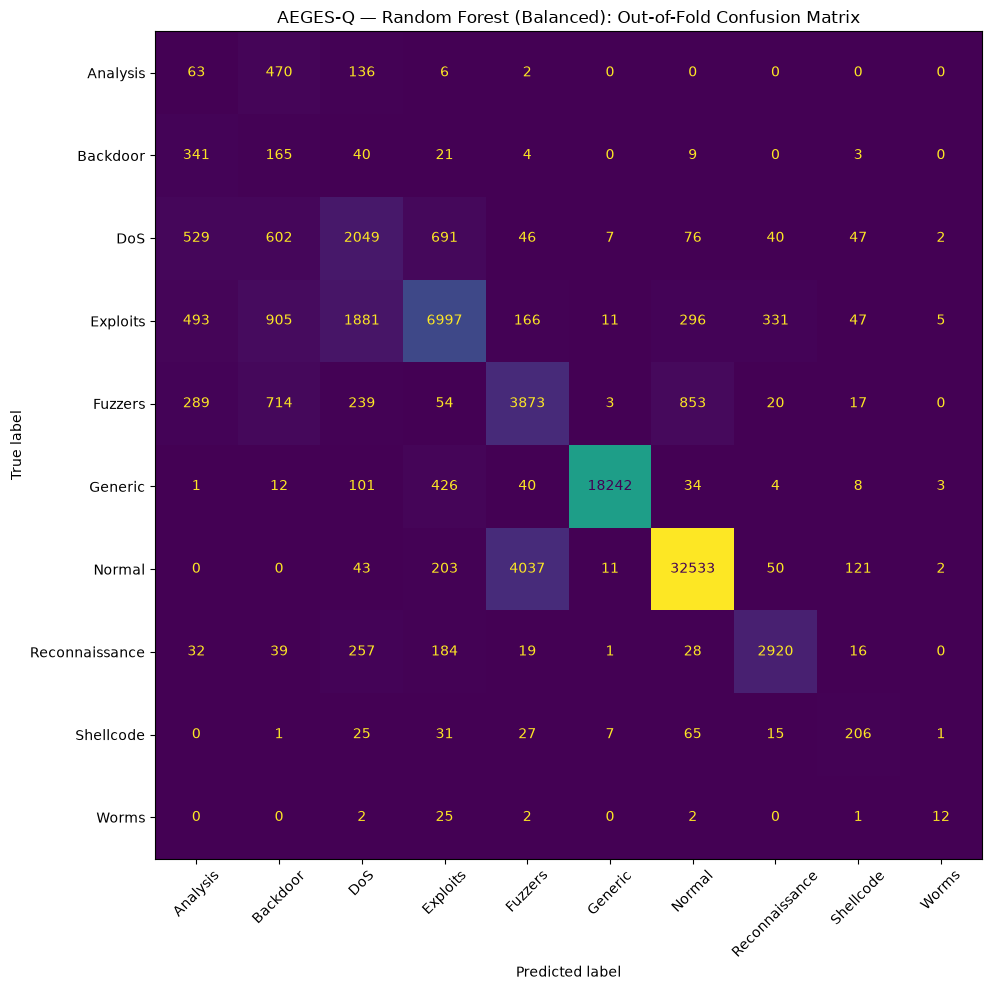

In [16]:
# Generate out-of-fold predictions for the selected candidate.
# Every row is predicted by a model that did not train on that row.

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_candidate_name = "random_forest_balanced"
selected_pipeline = cv_pipelines[selected_candidate_name]

oof_predictions = cross_val_predict(
    selected_pipeline,
    X,
    y,
    cv=cv,
    method="predict",
    n_jobs=1,
)

print("Out-of-fold predictions:", len(oof_predictions))
print("Matches training rows:", len(oof_predictions) == len(y))

print("\nOut-of-fold classification report:")
print(
    classification_report(
        y,
        oof_predictions,
        labels=sorted(y.unique()),
        zero_division=0,
        digits=4,
    )
)

oof_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=sorted(y.unique()),
)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(
    confusion_matrix=oof_cm,
    display_labels=sorted(y.unique()),
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False,
)
ax.set_title("AEGES-Q — Random Forest (Balanced): Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

## 15. Class-Weight Strategy Experiment

Out-of-fold evaluation reveals a substantial disparity between attack categories. The class-weighted Random Forest achieves strong results for `Generic`, `Normal`, and `Reconnaissance`, but struggles with `Analysis` and `Backdoor`. The confusion matrix also shows that these classes are frequently confused with one another.

This experiment evaluates alternative class-weighting strategies while keeping the Random Forest architecture and preprocessing pipeline fixed. The objective is to determine whether the current weighting scheme overemphasises minority classes without improving their precision.

Candidates will be compared using the same stratified folds. Macro-F1 remains the primary metric, with weighted-F1 and accuracy retained as secondary measures. Per-class precision and recall will be examined before choosing a configuration.

The official test set remains untouched during this experiment.

In [17]:
# Compare weighting strategies with identical stratified folds.
# The custom weights use square-root inverse frequency to soften rare-class weights.

from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier

class_counts = y.value_counts()
class_weights_sqrt = {
    cls: float(np.sqrt(len(y) / (len(class_counts) * count)))
    for cls, count in class_counts.items()
}

weighting_candidates = {
    "rf_unweighted": RandomForestClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "rf_balanced": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "rf_balanced_subsample": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "rf_sqrt_inverse_frequency": RandomForestClassifier(
        n_estimators=200,
        class_weight=class_weights_sqrt,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

weighting_results = []
weighting_fold_results = {}

for name, model in weighting_candidates.items():
    pipeline = Pipeline([
        ("preprocessor", build_variant_e_preprocessor()),
        ("classifier", model),
    ])

    print(f"\nEvaluating: {name}")

    result = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    weighting_fold_results[name] = result

    weighting_results.append({
        "model": name,
        "macro_f1_mean": result["test_macro_f1"].mean(),
        "macro_f1_std": result["test_macro_f1"].std(ddof=1),
        "weighted_f1_mean": result["test_weighted_f1"].mean(),
        "accuracy_mean": result["test_accuracy"].mean(),
        "fit_seconds_total": result["fit_time"].sum(),
    })

weighting_results_df = pd.DataFrame(weighting_results).sort_values(
    "macro_f1_mean", ascending=False
).reset_index(drop=True)

display(weighting_results_df)


Evaluating: rf_unweighted

Evaluating: rf_balanced

Evaluating: rf_balanced_subsample

Evaluating: rf_sqrt_inverse_frequency


,model,macro_f1_mean,macro_f1_std,weighted_f1_mean,accuracy_mean,fit_seconds_total
0,rf_balanced,0.539945,0.030010,0.835696,0.814507,368.032466
1,rf_sqrt_inverse_frequency,0.528965,0.015399,0.851245,0.843087,555.489356
2,rf_balanced_subsample,0.511559,0.012895,0.845838,0.840997,589.005148
3,rf_unweighted,0.500558,0.012287,0.836525,0.844836,397.829291


## 16. Feature-Level Investigation of Difficult Classes

Out-of-fold evaluation indicates that `Analysis` and `Backdoor` are among the most difficult attack categories for the current classifier. This section investigates their raw feature distributions and compares them with other classes.

The analysis uses the official training split only. It examines numerical feature summaries and categorical distributions without fitting a model or using the official test set.

The purpose is to identify potential data overlap, unusual feature distributions, or useful signals that may have been removed by the current Variant E feature-selection strategy. Any feature-engineering changes will be treated as a separate experiment and evaluated using the same leakage-safe cross-validation protocol.

In [18]:
 # Compare numerical feature distributions for Analysis and Backdoor.
# This is descriptive analysis on the official training split only.

focus_classes = ["Analysis", "Backdoor", "DoS", "Exploits", "Normal"]

numeric_cols = [
    col for col in REDUCED_NUMERICAL_FEATURES
    if col in train_df.columns
]

summary_frames = []

for attack_class in focus_classes:
    subset = train_df.loc[
        train_df[TARGET_COLUMN] == attack_class,
        numeric_cols
    ]

    summary = subset.median(numeric_only=True).to_frame("median")
    summary["attack_cat"] = attack_class
    summary["feature"] = summary.index
    summary["count"] = len(subset)
    summary_frames.append(summary.reset_index(drop=True))

numeric_medians = pd.concat(summary_frames, ignore_index=True)

median_pivot = numeric_medians.pivot(
    index="feature",
    columns="attack_cat",
    values="median"
)

# Rank features by the range of class medians, after robust scaling by
# the overall interquartile range to avoid ranking only by raw units.
overall_q75 = train_df[numeric_cols].quantile(0.75)
overall_q25 = train_df[numeric_cols].quantile(0.25)
iqr = (overall_q75 - overall_q25).replace(0, np.nan)

scaled_median_range = (
    median_pivot.max(axis=1) - median_pivot.min(axis=1)
) / iqr.reindex(median_pivot.index)

feature_separation = (
    pd.DataFrame({
        "median_range": median_pivot.max(axis=1) - median_pivot.min(axis=1),
        "scaled_median_range": scaled_median_range,
    })
    .sort_values("scaled_median_range", ascending=False)
)

print("Top 15 numerical features by scaled range of class medians:")
display(feature_separation.head(15))

print("\nClass median values for those features:")
display(
    median_pivot.loc[feature_separation.head(15).index]
)

Top 15 numerical features by scaled range of class medians:


,median_range,scaled_median_range
feature,,
sload,9.997547e+07,1.534975
ct_dst_sport_ltm,3.000000e+00,1.500000
rate,1.249442e+05,1.124787
ct_srv_dst,1.000000e+01,1.111111
ct_state_ttl,1.000000e+00,1.000000
sttl,1.920000e+02,1.000000
swin,2.550000e+02,1.000000
dttl,2.520000e+02,1.000000
ackdat,4.496200e-02,0.921046



Class median values for those features:


attack_cat,Analysis,Backdoor,DoS,Exploits,Normal
feature,,,,,
sload,1.000000e+08,8.000000e+07,8.888889e+07,24529.020505,91269.683595
ct_dst_sport_ltm,3.000000e+00,4.000000e+00,2.000000e+00,1.000000,1.000000
rate,1.250000e+05,1.000000e+05,1.111111e+05,55.849594,118.625534
ct_srv_dst,1.000000e+01,1.100000e+01,4.000000e+00,1.000000,4.000000
ct_state_ttl,2.000000e+00,2.000000e+00,2.000000e+00,1.000000,1.000000
sttl,2.540000e+02,2.540000e+02,2.540000e+02,254.000000,62.000000
swin,0.000000e+00,0.000000e+00,0.000000e+00,255.000000,255.000000
dttl,0.000000e+00,0.000000e+00,0.000000e+00,252.000000,29.000000
ackdat,0.000000e+00,0.000000e+00,0.000000e+00,0.044962,0.000146


## 17. Distribution Overlap: Analysis vs Backdoor

The preceding summary shows similar medians for `Analysis` and `Backdoor` across several numerical features. This section examines their distributions in greater detail.

Medians alone can hide multimodal distributions, skewness, and outliers. We will compare selected numerical features using quantiles and visualisations, and inspect the categorical feature distributions for the two classes.

This analysis uses the official training split only. It is exploratory and does not establish causal relationships or prove that the classes are inherently indistinguishable.

In [19]:
# Compare the full distributions of the two difficult classes.
# The analysis is descriptive and does not fit a model.

focus_pair = ["Analysis", "Backdoor"]

inspect_features = [
    "sload",
    "rate",
    "ct_dst_sport_ltm",
    "ct_srv_dst",
    "sttl",
    "dbytes",
    "dur",
]

pair_df = train_df.loc[
    train_df[TARGET_COLUMN].isin(focus_pair)
].copy()

quantiles = [0.00, 0.10, 0.25, 0.50, 0.75, 0.90, 1.00]

for feature in inspect_features:
    if feature not in pair_df.columns:
        continue

    print(f"\n{feature} — quantiles")
    display(
        pair_df.groupby(TARGET_COLUMN)[feature]
        .quantile(quantiles)
        .unstack()
        .rename(columns={
            0.0: "min",
            0.1: "p10",
            0.25: "p25",
            0.5: "median",
            0.75: "p75",
            0.9: "p90",
            1.0: "max",
        })
    )

for feature in CATEGORICAL_FEATURES:
    print(f"\n{feature} — proportions within each class")
    display(
        pd.crosstab(
            pair_df[TARGET_COLUMN],
            pair_df[feature],
            normalize="index",
        ).round(3)
    )


sload — quantiles


,min,p10,p25,median,p75,p90,max
attack_cat,,,,,,,
Analysis,311.757538,13722.613868,72727272.0,100000000.0,160000000.0,266666656.0,8.000000e+08
Backdoor,0.000000,8914.725391,72727272.0,80000000.0,160000000.0,266666656.0,1.034667e+09



rate — quantiles


,min,p10,p25,median,p75,p90,max
attack_cat,,,,,,,
Analysis,0.416642,38.263655,90909.0902,125000.0003,200000.0051,333333.3215,1000000.003
Backdoor,0.000000,27.328458,90909.0902,100000.0025,200000.0051,333333.3215,1000000.003



ct_dst_sport_ltm — quantiles


...

proto,3pc,a/n,aes-sp3-d,any,argus,aris,ax.25,bbn-rcc,bna,br-sat-mon,...,visa,vmtp,vrrp,wb-expak,wb-mon,wsn,xnet,xns-idp,xtp,zero
attack_cat,,,,,,,,,,,,,,,,,,,,,
Analysis,0.004,0.004,0.004,0.013,0.004,0.004,0.004,0.004,0.004,0.004,...,0.004,0.004,0.004,0.004,0.004,0.004,0.004,0.004,0.004,0.004
Backdoor,0.003,0.003,0.003,0.010,0.005,0.003,0.003,0.005,0.003,0.003,...,0.003,0.003,0.003,0.003,0.003,0.003,0.005,0.005,0.003,0.003



service — proportions within each class


service,-,ftp,http
attack_cat,,,
Analysis,1.000,0.000,0.000
Backdoor,0.981,0.003,0.015



state — proportions within each class


state,CON,FIN,INT,REQ
attack_cat,,,,
Analysis,0.001,0.084,0.914,0.000
Backdoor,0.010,0.087,0.895,0.007


## 18. Experiment Conclusion and Candidate Selection

The multiclass IDS experiment compared baseline classifiers, evaluated tree-ensemble capacity settings, and assessed class-weighting strategies using stratified five-fold cross-validation.

The class-weighted Random Forest achieved the highest mean validation macro-F1 among the evaluated candidates: **0.5399 ± 0.0300**. Its mean weighted-F1 was 0.8357 and mean accuracy was 0.8145.

Out-of-fold analysis revealed substantial class-specific differences. Performance was strong for `Generic`, `Normal`, and `Reconnaissance`, while `Analysis` and `Backdoor` remained difficult to distinguish. Feature-distribution analysis showed considerable overlap between these two classes across several numerical features, although this descriptive evidence does not establish that they are inherently inseparable.

The class-weighted Random Forest is selected for final evaluation because it achieved the best mean macro-F1 under the predefined comparison protocol. No further model-family exploration or hyperparameter search is included in this experiment.

The selected configuration will be refitted on the complete official training split. The official test split will then be evaluated once to measure final performance. Test results will be reported without further model selection or tuning.

The model's suitability for deployment will be assessed against its measured class-wise performance and the intended use of the IDS. Any limitations, particularly for minority attack categories, will be documented explicitly.